# Wyndham 1CD EBM Model Test

**Note: Make sure you upload these files to the `/content` folder before runnning:**
- `bookings_train_may_june_.parquet`
- `bookings_test_july_.parquet`

**Model Setup**
1. Only looked at member no-shows and late cancels (QNS/QXY), since that's the only place this fraud happens.
2. Using two feature sets, with what Murtaza used and some more features I added.
3. Trained on May + June, tested on July.
4. Test ran a stricter **unseen-accounts** test, since the same fraud accounts appear every month

In [4]:
!pip install -q interpret-core shap

In [5]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

FOLDER = "/content/"
TRAIN_FILE = FOLDER + "bookings_train_may_june.parquet"
TEST_FILE = FOLDER + "bookings_test_july.parquet"


## Loading Data
`points_redeemed` is left out on purpose (Danielle said it happens too late to use).

In [6]:
COLS = ["confirmation_number", "member_number", "booking_timestamp", "check_in_date", "cancellation_date",
        "rate_code", "room_revenue", "points_earned", "booking_channel", "qualification_code",
        "member_enrollment_date", "member_enrollment_source", "first_name", "last_name", "email",
        "phone_number", "data_month", "is_fraud"]

all_rows = pd.concat([pd.read_parquet(TRAIN_FILE, columns=COLS),
                      pd.read_parquet(TEST_FILE, columns=COLS)], ignore_index=True)
print(all_rows.shape)
print(all_rows.groupby("data_month")["is_fraud"].sum())

(9600000, 18)
data_month
july    1600
june    1600
may     1600
Name: is_fraud, dtype: int32


## Per-account facts (from all bookings)
Two clues need the account's whole history, so we compute them before filtering:
- **first booking date** → `account_age_at_first_booking`. Unlike age-at-booking, this doesn't grow month to month for the same account.
- **accounts sharing a phone prefix** (first 9 digits): fake accounts often reuse numbers.

In [7]:
members = all_rows[all_rows["member_number"].notna()]
first_booking = (pd.to_datetime(members["booking_timestamp"]).dt.tz_localize(None)
                 .groupby(members["member_number"]).min().dt.normalize())

prefix = members["phone_number"].astype(str).str.replace(r"\D", "", regex=True).str[:9]
pairs = pd.DataFrame({"member_number": members["member_number"], "prefix": prefix}).drop_duplicates()
pairs["n_members"] = pairs.groupby("prefix")["member_number"].transform("count")
phone_sharing = pairs.groupby("member_number")["n_members"].max()
print(len(first_booking), "members")

700400 members


## Keep member no-shows and late cancels only

In [8]:
df = all_rows[all_rows["qualification_code"].isin(["QNS", "QXY"]) & all_rows["member_number"].notna()].copy()
del all_rows, members
print(df.groupby("data_month")["is_fraud"].agg(["count", "sum"]))   # 32,000 rows / 1,600 fraud per month

            count   sum
data_month             
july        32000  1600
june        32000  1600
may         32000  1600


## Feature engineering
**Murtaza's features** (same names and definitions as in the team doc), plus `room_revenue`, `points_earned` and `booking_channel`, which were his top features (all confirmed valid by Danielle):

| Feature | Meaning |
| --- | --- |
| `lead_time_days` | days between booking date and check-in date |
| `account_age_days` | days between enrollment and booking |
| `is_digital` | booked on Mobile App or Website |
| `is_sdc4` | rate code SDC4 |
| `is_srb` | rate code SRB (free night redemption) |
| `is_gmail_or_outlook` | Gmail or Outlook email |

**Extra features added:**

| Feature | Why |
| --- | --- |
| `account_age_at_first_booking` | stable version of account age (doesn't drift across months) |
| `enrolled_within_30d` | Danielle's confirmed signal: fraudsters enroll within 30 days of their first booking |
| `enrolled_online` | fraud only enrolls via web/app |
| `is_late_cancel`, `cancel_same_day_as_booking` | second fraud method; book then cancel same day |
| `email_initial_lastname_format` | 66% of fraud emails look like jsmith@, 0% of normal |
| `members_sharing_phone_prefix` | fake accounts reuse phone numbers |
| `m_mtd_noshows` | member's earlier no-shows this month |

In [9]:
booking_date = pd.to_datetime(df["booking_timestamp"]).dt.tz_localize(None).dt.normalize()
check_in = pd.to_datetime(df["check_in_date"])
enrolled = pd.to_datetime(df["member_enrollment_date"])

# Murtaza's features
df["lead_time_days"] = (check_in - booking_date).dt.days
df["account_age_days"] = (booking_date - enrolled).dt.days
df["is_digital"] = df["booking_channel"].isin(["Website", "Mobile App"]).astype(int)
df["is_sdc4"] = (df["rate_code"] == "SDC4").astype(int)
df["is_srb"] = (df["rate_code"] == "SRB").astype(int)
email = df["email"].str.lower()
df["is_gmail_or_outlook"] = email.str.split("@").str[1].isin(["gmail.com", "outlook.com"]).astype(int)

# Added features
df["account_age_at_first_booking"] = (first_booking.reindex(df["member_number"]).values - enrolled.values).astype("timedelta64[D]").astype(int)
df["enrolled_within_30d"] = (df["account_age_at_first_booking"] <= 30).astype(int)
df["enrolled_online"] = df["member_enrollment_source"].isin(["ONLINE_WEB", "ONLINE_APP"]).astype(int)
df["is_late_cancel"] = (df["qualification_code"] == "QXY").astype(int)
df["cancel_same_day_as_booking"] = (pd.to_datetime(df["cancellation_date"]) == booking_date).astype(int)
handle = email.str.split("@").str[0].fillna("")
first = df["first_name"].str.lower().str.replace(r"[^a-z]", "", regex=True).fillna("")
last = df["last_name"].str.lower().str.replace(r"[^a-z]", "", regex=True).fillna("")
df["email_initial_lastname_format"] = [int(h.startswith(f[:1] + l) and not h.startswith(f + l)) if f and l else 0
                                       for h, f, l in zip(handle, first, last)]
df["members_sharing_phone_prefix"] = phone_sharing.reindex(df["member_number"]).values
df = df.sort_values(["member_number", "check_in_date"])
df["m_mtd_noshows"] = df.groupby(["member_number", "data_month"]).cumcount()

MURTAZA = ["lead_time_days", "account_age_days", "is_digital", "is_sdc4", "is_srb", "is_gmail_or_outlook",
           "room_revenue", "points_earned", "booking_channel"]
EXTRA = ["account_age_at_first_booking", "enrolled_within_30d", "enrolled_online", "is_late_cancel",
         "cancel_same_day_as_booking", "email_initial_lastname_format", "members_sharing_phone_prefix", "m_mtd_noshows"]
FEATURE_SETS = {"MURTAZA": MURTAZA, "EXTENDED": MURTAZA + EXTRA}

# fraud (1) vs normal (0): big gaps = strong clues
df.groupby("is_fraud")[[c for c in MURTAZA + EXTRA if c != "booking_channel"]].mean().round(2).T

is_fraud,0,1
lead_time_days,42.11,0.26
account_age_days,2717.25,44.43
is_digital,0.20,1.00
is_sdc4,0.09,0.55
is_srb,0.00,0.00
is_gmail_or_outlook,0.68,0.83
room_revenue,180.73,845.98
points_earned,1963.67,13093.72
account_age_at_first_booking,2605.46,10.46
enrolled_within_30d,0.11,1.00


In [10]:
# account age at booking drifts month to month for the same fraud accounts (a known synthetic-data issue);
# age at first booking stays stable
df[df["is_fraud"] == 1].groupby("data_month")[["account_age_days", "account_age_at_first_booking"]].agg(["min", "median", "max"])

account_age_days            account_age_at_first_booking           
                        min median max                          min median max
data_month                                                                    
july                     63   75.0  89                            1   10.0  19
june                     33   45.0  59                            1   10.0  19
may                       1   14.0  28                            1   10.0  19

## Train/test splits
- **Test A:** train on all May + June, test on all of July.
- **Test B (stricter):** the same fraud accounts appear every month, so hold out 30% of accounts entirely. Train on May + June from the other 70%, test on July from the held-out 30%.

In [11]:
train_A = df[df["data_month"].isin(["may", "june"])]
test_A = df[df["data_month"] == "july"]

rng = np.random.RandomState(42)
fraud_accts = np.sort(df.loc[df["is_fraud"] == 1, "member_number"].unique())
normal_accts = np.setdiff1d(df["member_number"].unique(), fraud_accts)
held_out = set(rng.choice(fraud_accts, int(0.3 * len(fraud_accts)), replace=False)) | \
           set(rng.choice(normal_accts, int(0.3 * len(normal_accts)), replace=False))
train_B = train_A[~train_A["member_number"].isin(held_out)]
test_B = test_A[test_A["member_number"].isin(held_out)]

SPLITS = {"A: July": (train_A, test_A), "B: July, unseen accounts": (train_B, test_B)}
for name, (tr, te) in SPLITS.items():
    print(f"{name}: train {len(tr)} ({tr.is_fraud.sum()} fraud) | test {len(te)} ({te.is_fraud.sum()} fraud)")

A: July: train 64000 (3200 fraud) | test 32000 (1600 fraud)
B: July, unseen accounts: train 44894 (2272 fraud) | test 9615 (464 fraud)


## Train and evaluate
The cutoff is chosen on a validation slice of the **training** data (never July): halfway between the riskiest normal booking and the least risky fraud booking, on the model's raw score (log-odds). We also report **false alarms at 80% of fraud caught** (Danielle's minimum bar), which doesn't depend on the cutoff.

In [12]:
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, precision_recall_curve)

SETTINGS = dict(interactions=5, outer_bags=4, max_rounds=2000, random_state=42)   # fast settings

def pick_cutoff(train_df, features):
    """Fit on 80% of training accounts, then set the cutoff on the other 20%.
    Uses the model's raw score (log-odds), since probabilities sit too close to 0 and 1 to compare.
    Cutoff = halfway between the highest-scoring normal booking and the lowest-scoring fraud booking;
    if they overlap, the score with the best F1 on the validation slice."""
    fit_idx, val_idx = next(GroupShuffleSplit(1, test_size=0.2, random_state=42).split(train_df, groups=train_df["member_number"]))
    fit, val = train_df.iloc[fit_idx], train_df.iloc[val_idx]
    m = ExplainableBoostingClassifier(**SETTINGS).fit(fit[features], fit["is_fraud"])
    score, y = m.decision_function(val[features]), val["is_fraud"].values
    lo, hi = score[y == 0].max(), score[y == 1].min()
    if hi > lo:
        return float((lo + hi) / 2)
    candidates = np.unique(np.quantile(score, np.linspace(0.80, 0.999, 300)))
    return float(max(candidates, key=lambda t: f1_score(y, (score >= t).astype(int))))

def false_alarms_at_recall(y, prob, target=0.80):
    order = np.argsort(-prob); y_sorted = np.asarray(y)[order]
    k = np.searchsorted(np.cumsum(y_sorted), np.ceil(target * y_sorted.sum())) + 1
    return int(k - y_sorted[:k].sum())

def run(features, train_df, test_df):
    cutoff = pick_cutoff(train_df, features)
    start = time.time()
    model = ExplainableBoostingClassifier(**SETTINGS).fit(train_df[features], train_df["is_fraud"])
    secs = round(time.time() - start, 1)
    y, prob = test_df["is_fraud"], model.predict_proba(test_df[features])[:, 1]
    pred = (model.decision_function(test_df[features]) >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return model, prob, {
        "n_samples": len(y), "fraud_count": int(y.sum()), "fraud_prevalence": round(float(y.mean()), 4),
        "precision": round(precision_score(y, pred, zero_division=0), 4), "recall": round(recall_score(y, pred), 4),
        "f1_score": round(f1_score(y, pred), 4), "roc_auc": round(roc_auc_score(y, prob), 4),
        "average_precision_pr_auc": round(average_precision_score(y, prob), 4),
        "true_negatives": int(tn), "false_positives": int(fp), "false_negatives": int(fn), "true_positives": int(tp),
        "false_alarms_at_80pct_recall": false_alarms_at_recall(y, prob),
        "decision_threshold_logodds": round(cutoff, 2), "training_time_seconds": secs}

results, models = [], {}
for set_name, feats in FEATURE_SETS.items():
    for split_name, (tr, te) in SPLITS.items():
        model, prob, m = run(feats, tr, te)
        models[(set_name, split_name)] = (model, prob, te, feats)
        results.append({"features": set_name, "test": split_name, **m})
        print(f"done: {set_name} | {split_name}")

results = pd.DataFrame(results)
results[["features", "test", "true_positives", "false_negatives", "false_positives", "precision", "recall",
         "average_precision_pr_auc", "false_alarms_at_80pct_recall", "training_time_seconds"]]

done: MURTAZA | A: July
done: MURTAZA | B: July, unseen accounts
done: EXTENDED | A: July
done: EXTENDED | B: July, unseen accounts


,features,test,true_positives,false_negatives,false_positives,precision,recall,average_precision_pr_auc,false_alarms_at_80pct_recall,training_time_seconds
0,MURTAZA,A: July,1600,0,0,1.0,1.0,1.0,0,22.6
1,MURTAZA,"B: July, unseen accounts",464,0,0,1.0,1.0,1.0,0,12.9
2,EXTENDED,A: July,1600,0,0,1.0,1.0,1.0,0,13.7
3,EXTENDED,"B: July, unseen accounts",464,0,0,1.0,1.0,1.0,0,9.8


Full metrics for the main result (extended features, unseen accounts), in the same format as the team doc:

In [13]:
print(json.dumps(results[(results.features == "EXTENDED") & (results.test == "B: July, unseen accounts")].iloc[0].to_dict(), indent=4, default=str))

{
    "features": "EXTENDED",
    "test": "B: July, unseen accounts",
    "n_samples": 9615,
    "fraud_count": 464,
    "fraud_prevalence": 0.0483,
    "precision": 1.0,
    "recall": 1.0,
    "f1_score": 1.0,
    "roc_auc": 1.0,
    "average_precision_pr_auc": 1.0,
    "true_negatives": 9151,
    "false_positives": 0,
    "false_negatives": 0,
    "true_positives": 464,
    "false_alarms_at_80pct_recall": 0,
    "decision_threshold_logodds": -0.08,
    "training_time_seconds": 9.8
}


## Precision-recall curves

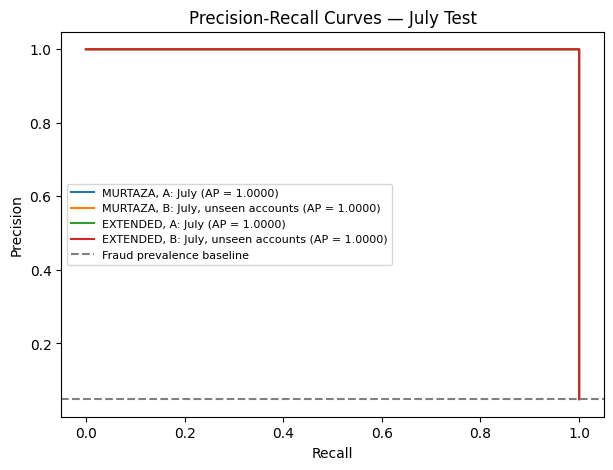

In [14]:
plt.figure(figsize=(7, 5))
for (set_name, split_name), (model, prob, te, feats) in models.items():
    p, r, _ = precision_recall_curve(te["is_fraud"], prob)
    plt.step(r, p, where="post", label=f"{set_name}, {split_name} (AP = {average_precision_score(te['is_fraud'], prob):.4f})")
plt.axhline(test_A["is_fraud"].mean(), linestyle="--", color="gray", label="Fraud prevalence baseline")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall Curves — July Test")
plt.legend(fontsize=8); plt.show()

## What the model relies on
Extended features, unseen-accounts test. EBM is additive, so each prediction is exactly the sum of per-feature contributions (`eval_terms`); the SHAP-style plots draw those. For text columns like `booking_channel`, colors follow alphabetical order, so only read colors on number columns.

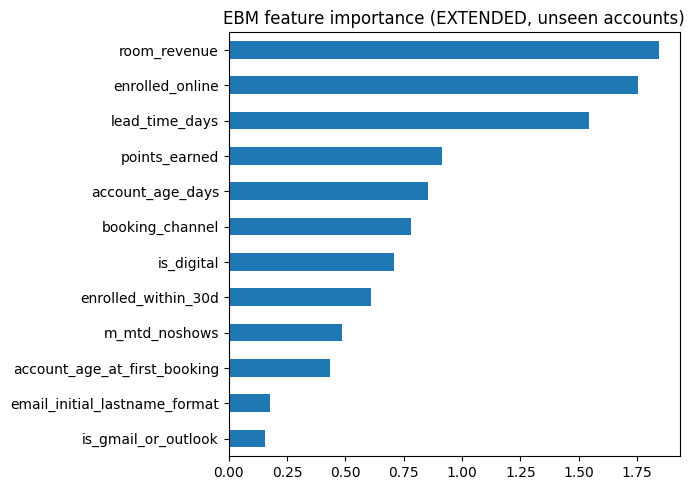

In [15]:
model, prob, te, feats = models[("EXTENDED", "B: July, unseen accounts")]
pd.Series(model.term_importances(), index=model.term_names_).sort_values().tail(12).plot.barh(
    figsize=(7, 5), title="EBM feature importance (EXTENDED, unseen accounts)")
plt.tight_layout(); plt.show()

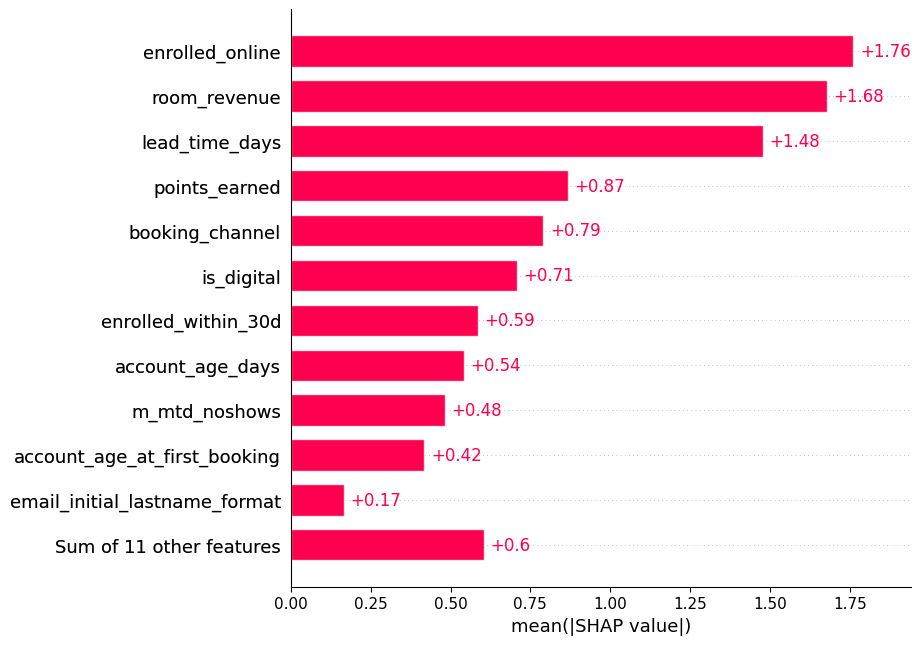

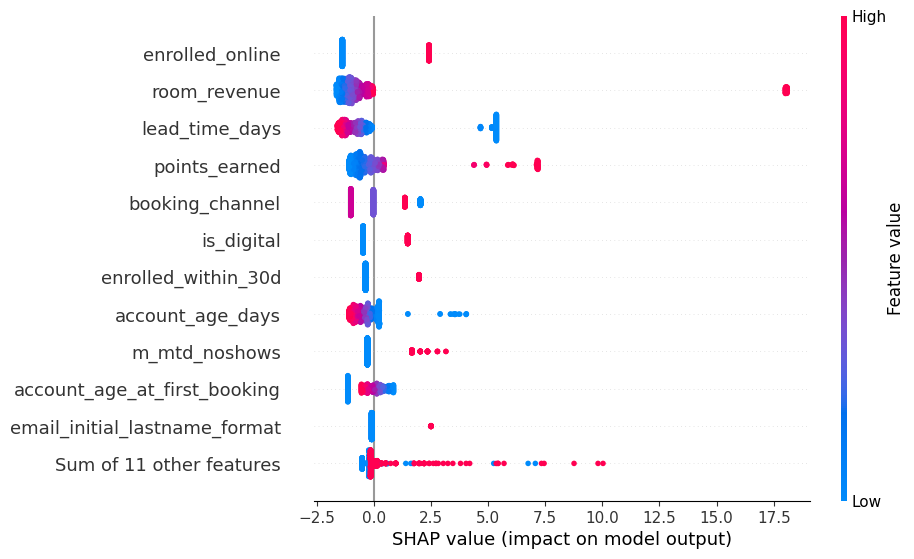

In [16]:
import shap
sample = te[feats].sample(min(1000, len(te)), random_state=42)
contrib = model.eval_terms(sample)
color_data = np.full(contrib.shape, np.nan)
for j, name in enumerate(model.term_names_):
    if name in sample.columns:
        col = sample[name]
        color_data[:, j] = col.values if col.dtype.kind in "if" else col.astype("category").cat.codes.values
exp = shap.Explanation(values=contrib, data=color_data, feature_names=list(model.term_names_))
shap.plots.bar(exp, max_display=12)
shap.plots.beeswarm(exp, max_display=12)

## Why one booking was flagged (what an analyst would see)

In [17]:
score = model.decision_function(te[feats])
cutoff = results.query("features == 'EXTENDED' and test == 'B: July, unseen accounts'")["decision_threshold_logodds"].iloc[0]
flagged = np.where(score >= cutoff)[0]
i = flagged[0] if len(flagged) else int(np.argmax(score))   # fall back to the riskiest booking
pushes = pd.Series(model.eval_terms(te[feats].iloc[[i]])[0], index=model.term_names_).sort_values(ascending=False)
print("risk score (log-odds):", round(float(score[i]), 2), "| actually fraud:", int(te["is_fraud"].iloc[i]))
pushes.head(5).round(2)

risk score (log-odds): 18.39 | actually fraud: 1


,0
room_revenue,18.00
lead_time_days,5.36
points_earned,4.94
email_initial_lastname_format,2.50
enrolled_online,2.42


## Robustness check: without revenue and points
Price separates fraud almost perfectly in this synthetic data. Danielle confirmed it's valid to use, but a fraudster could book cheaper rooms, so check how the model does without it.

We run it twice: without price, and without price *and* `account_age_days`. That feature grows ~30 days a month for the same fraud accounts (see step 4), so a cutoff learned on May/June can miss July fraud even when the ranking is perfect.

In [18]:
KEYS = ["true_positives", "false_negatives", "false_positives", "precision", "recall",
        "average_precision_pr_auc", "false_alarms_at_80pct_recall"]
NO_PRICE = [f for f in FEATURE_SETS["EXTENDED"] if f not in ("room_revenue", "points_earned")]
NO_PRICE_NO_DRIFT = [f for f in NO_PRICE if f != "account_age_days"]   # also drop the drifting age-at-booking

for name, feats_ in [("no price", NO_PRICE), ("no price, no account_age_days", NO_PRICE_NO_DRIFT)]:
    _, _, m_ = run(feats_, train_B, test_B)
    print(name, json.dumps({k: m_[k] for k in KEYS}))

no price {"true_positives": 117, "false_negatives": 347, "false_positives": 0, "precision": 1.0, "recall": 0.2522, "average_precision_pr_auc": 1.0, "false_alarms_at_80pct_recall": 0}
no price, no account_age_days {"true_positives": 451, "false_negatives": 13, "false_positives": 0, "precision": 1.0, "recall": 0.972, "average_precision_pr_auc": 1.0, "false_alarms_at_80pct_recall": 0}


## Notes
- Rows are member no-shows/late cancels only (5% fraud), not all bookings, so compare with teammates only on the same rows.
- June and July reuse May's fraud accounts (a synthetic-data issue Danielle confirmed). Test B controls for that; the September dataset will be the cleaner test.
- `is_srb` is always 0 among no-shows (free-night redemptions don't appear here), so it adds nothing in this setup.

## Findings
- No price = very low recall (25%) since model thinks fraud accounts are always new, so older accounts (from July) are less suspicious and fell below cutoff
- No price + no account age = high recall (97%) since it uses other clues rather than depending on account age heavily

## Conclusion
- account_age_days is risky across months, swap it with account_age_at_first_booking
- Ranking quality and cutoff quality are different, meaning a model can rank perfectly and stuff miss fraud if the cutoff is in the wrong place.